In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

plt.rcParams["figure.figsize"] = (12, 4)
KAGGLE_DATASET = "fedesoriano/traffic-prediction-dataset"
DATA_PATH = Path(kagglehub.dataset_download(KAGGLE_DATASET)) / "traffic.csv"

/Users/oskarmulcan/.venvs/scf/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data read & quality control

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["DateTime"])
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   DateTime  48120 non-null  datetime64[us]
 1   Junction  48120 non-null  int64         
 2   Vehicles  48120 non-null  int64         
 3   ID        48120 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 1.5 MB


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [3]:
# Timespan and number of observations per junction
df.groupby("Junction")["DateTime"].agg(["min", "max", "count"])

,min,max,count
Junction,,,
1,2015-11-01,2017-06-30 23:00:00,14592
2,2015-11-01,2017-06-30 23:00:00,14592
3,2015-11-01,2017-06-30 23:00:00,14592
4,2017-01-01,2017-06-30 23:00:00,4344


In [4]:
print("Duplicates:", df.duplicated(subset=["DateTime", "Junction"]).sum())
print("NaN:", df["Vehicles"].isna().sum())
df["Vehicles"].describe()

Duplicates: 0
NaN: 0


count    48120.000000
mean        22.791334
std         20.750063
min          1.000000
25%          9.000000
50%         15.000000
75%         29.000000
max        180.000000
Name: Vehicles, dtype: float64

In [5]:
wide = df.pivot_table(index="DateTime", columns="Junction", values="Vehicles", aggfunc="mean")
wide.columns = [f"J{c}" for c in wide.columns]
full_index = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_index).rename_axis("DateTime")

# Missing data inside the range for each junction
for col in wide.columns:
    s = wide[col].dropna()
    inside = wide[col].loc[s.index.min():s.index.max()]
    print(col, "missing:", inside.isna().sum())

J1 missing: 0
J2 missing: 0
J3 missing: 0
J4 missing: 0


In [6]:
# Number of continuous gaps (in hours) for each junction
for col in wide.columns:
    s = wide[col].dropna()
    inside = wide[col].loc[s.index.min():s.index.max()]
    gap_id = inside.notna().cumsum()
    gaps = inside[inside.isna()].groupby(gap_id[inside.isna()]).size()
    print(col, "number of gaps:", len(gaps), "longest:", gaps.max() if len(gaps) else 0)

J1 number of gaps: 0 longest: 0
J2 number of gaps: 0 longest: 0
J3 number of gaps: 0 longest: 0
J4 number of gaps: 0 longest: 0


## 2. Visualizations

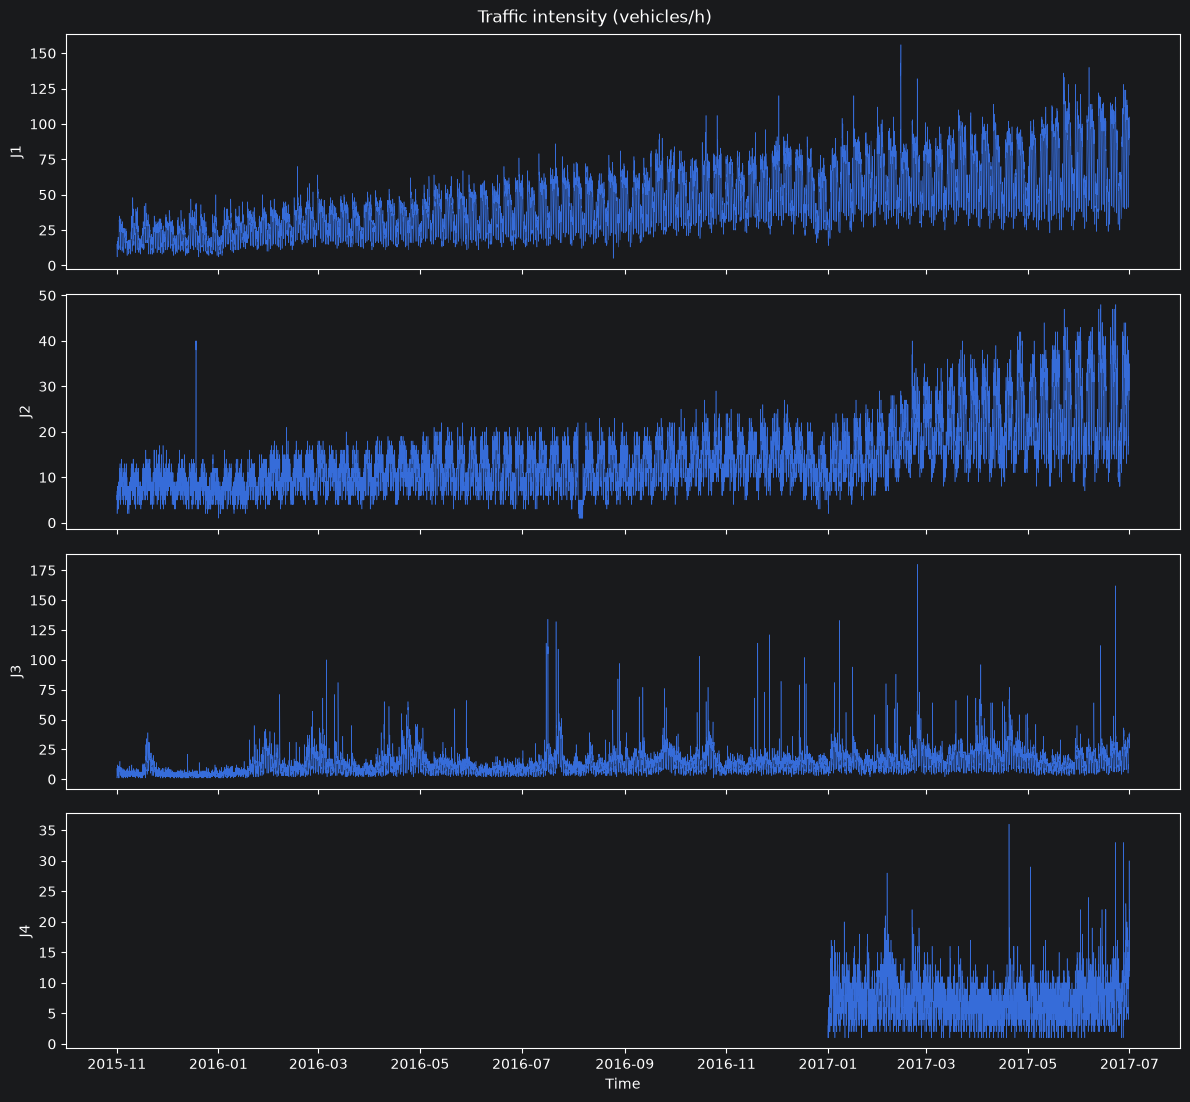

In [7]:
fig, axes = plt.subplots(len(wide.columns), 1, figsize=(12, 2.8 * len(wide.columns)), sharex=True)
for ax, col in zip(axes, wide.columns, strict=True):
    ax.plot(wide.index, wide[col], lw=0.4)
    ax.set_ylabel(col)
axes[-1].set_xlabel("Time")
fig.suptitle("Traffic intensity (vehicles/h)")
plt.tight_layout()

<Axes: title={'center': 'Weekly average'}, xlabel='DateTime'>

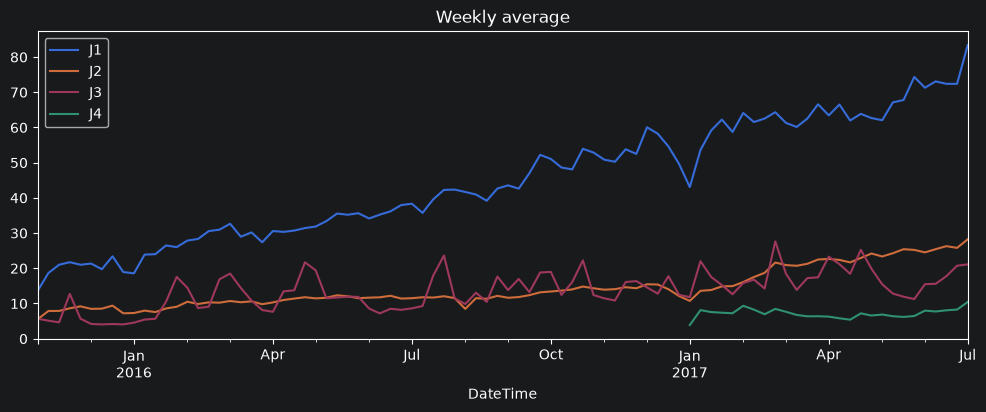

In [8]:
wide.resample("W").mean().plot(figsize=(12, 4), title="Weekly average")

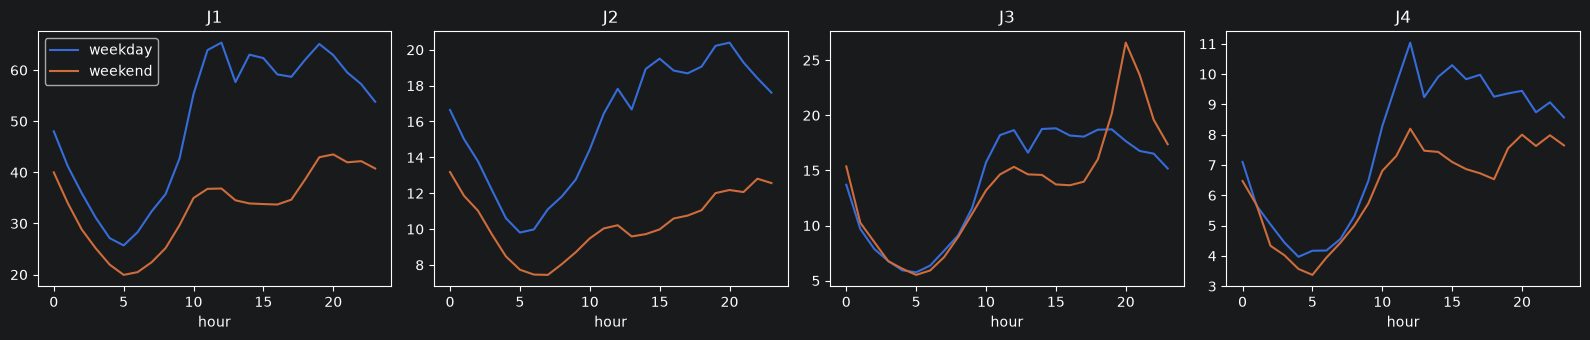

In [9]:
tmp = wide.copy()
tmp["hour"] = tmp.index.hour
tmp["weekend"] = tmp.index.day_of_week >= 5

fig, axes = plt.subplots(1, len(wide.columns), figsize=(4 * len(wide.columns), 3.5))
for ax, col in zip(axes, wide.columns, strict=True):
    for label, g in tmp.groupby("weekend"):
        ax.plot(g.groupby("hour")[col].mean(), label="weekend" if label else "weekday")
    ax.set_title(col)
    ax.set_xlabel("hour")
axes[0].legend()
plt.tight_layout()

<Axes: title={'center': 'Average intensity by the day of the week'}, xlabel='dow'>

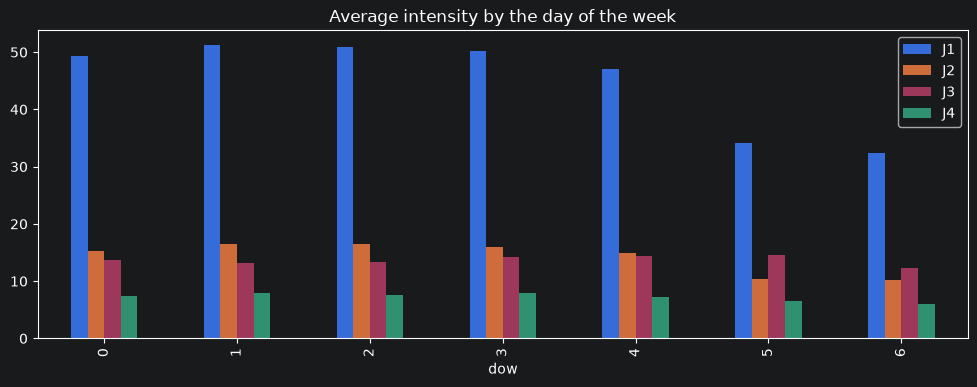

In [10]:
tmp["dow"] = tmp.index.day_of_week
tmp.groupby("dow")[list(wide.columns)].mean().plot(
    kind="bar", title="Average intensity by the day of the week"
)

Text(0.5, 1.0, 'J1: hour x day of the week')

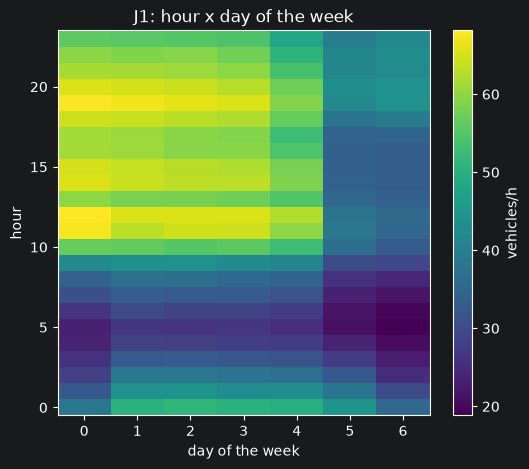

In [11]:
col = "J1"
pivot = tmp.pivot_table(index="hour", columns="dow", values=col, aggfunc="mean")
plt.figure(figsize=(6, 5))
plt.imshow(pivot, aspect="auto", origin="lower")
plt.colorbar(label="vehicles/h")
plt.xlabel("day of the week")
plt.ylabel("hour")
plt.title(f"{col}: hour x day of the week")

## 3. Seasonality and autocorrelation

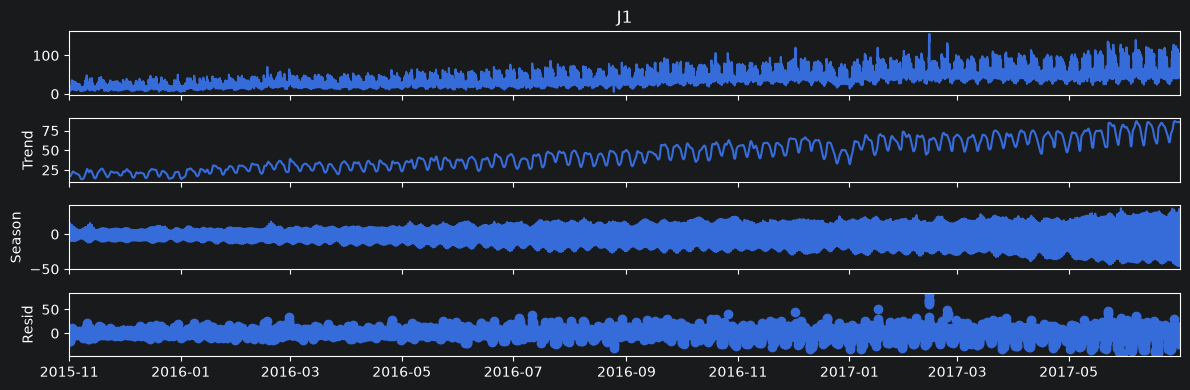

In [12]:
col = "J1"
series = wide[col].dropna().interpolate(limit=3)
res = STL(series, period=24, robust=True).fit()
res.plot()
plt.tight_layout()

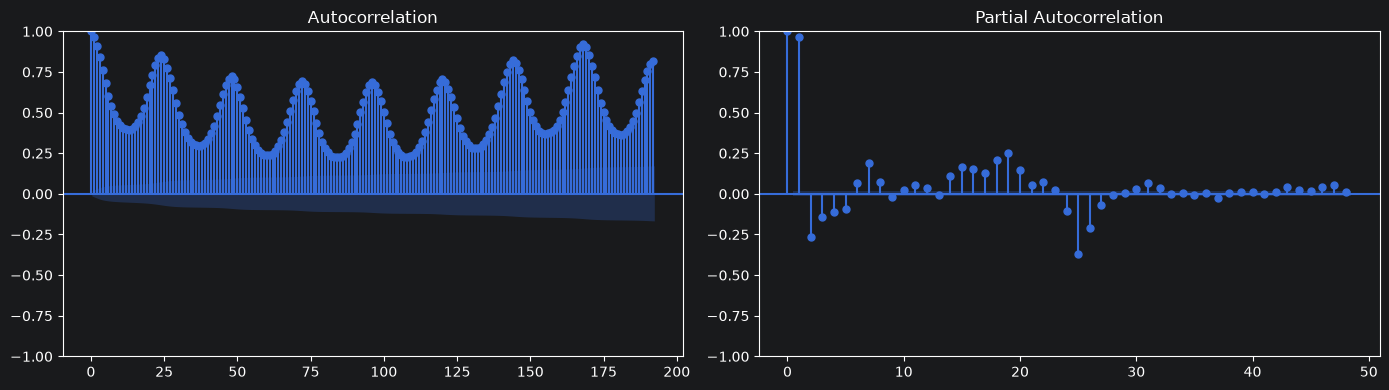

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(series, lags=24 * 8, ax=axes[0])
plot_pacf(series, lags=48, ax=axes[1])
plt.tight_layout()

## 4. Junctions comparison

In [14]:
wide.describe().T

,count,mean,std,min,25%,50%,75%,max
J1,14592.0,45.052906,23.008345,5.0,27.0,40.0,59.0,156.0
J2,14592.0,14.253221,7.401307,1.0,9.0,13.0,17.0,48.0
J3,14592.0,13.694010,10.436005,1.0,7.0,11.0,18.0,180.0
J4,4344.0,7.251611,3.521455,1.0,5.0,7.0,9.0,36.0


In [15]:
wide.dropna().corr()

,J1,J2,J3,J4
J1,1.000000,0.827574,0.514610,0.592566
J2,0.827574,1.000000,0.378791,0.396314
J3,0.514610,0.378791,1.000000,0.485609
J4,0.592566,0.396314,0.485609,1.000000


In [16]:
wide.quantile([0.05, 0.5, 0.95, 0.99]).T

,0.05,0.50,0.95,0.99
J1,15.0,40.0,89.0,108.09
J2,6.0,13.0,30.0,38.00
J3,3.0,11.0,30.0,51.00
J4,2.0,7.0,13.0,18.00
